# Exercício 1 — Valores Ausentes
**Disciplina:** Ciência de Dados · **Etapa CRISP-DM:** Preparação dos Dados
**Dataset:** Melbourne Housing Snapshot (`melb_data.csv`)

**Objetivo de negócio:** preparar a base de vendas de imóveis de Melbourne para uma análise de preços, decidindo com critério o que fazer com cada coluna que tem dados faltando.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 140)

In [2]:
# CARREGAMENTO DOS DADOS
df = pd.read_csv('melb_data.csv')

## Diagnóstico inicial

In [3]:
# DIAGNÓSTICO INICIAL
print('Dimensões (linhas, colunas):', df.shape)
print('Linhas duplicadas:', df.duplicated().sum())
print()
diag = pd.DataFrame({'tipo': df.dtypes.astype(str), 'ausentes': df.isna().sum(), 'valores_unicos': df.nunique()})
diag

Dimensões (linhas, colunas): (13580, 21)
Linhas duplicadas: 0



,tipo,ausentes,valores_unicos
Suburb,str,0,314
Address,str,0,13378
Rooms,int64,0,9
Type,str,0,3
Price,float64,0,2204
Method,str,0,5
SellerG,str,0,268
Date,str,0,58
Distance,float64,0,202
Postcode,float64,0,198


**Leitura do diagnóstico:** a base tem 13.580 imóveis e 21 colunas. Só 4 colunas têm valores ausentes (`Car`, `BuildingArea`, `YearBuilt` e `CouncilArea`); as outras 17 estão completas.

## Resumo de valores ausentes (quantidade e %)

In [4]:
# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
resumo = pd.DataFrame({
    'ausentes': df.isna().sum(),
    'pct_ausentes': df.isna().mean() * 100,
    'tipo': df.dtypes.astype(str),
})
resumo = resumo[resumo['ausentes'] > 0].sort_values('ausentes', ascending=False)
resumo

,ausentes,pct_ausentes,tipo
BuildingArea,6450,47.50,float64
YearBuilt,5375,39.58,float64
CouncilArea,1369,10.08,str
Car,62,0.46,float64


## Visualização do padrão de ausência

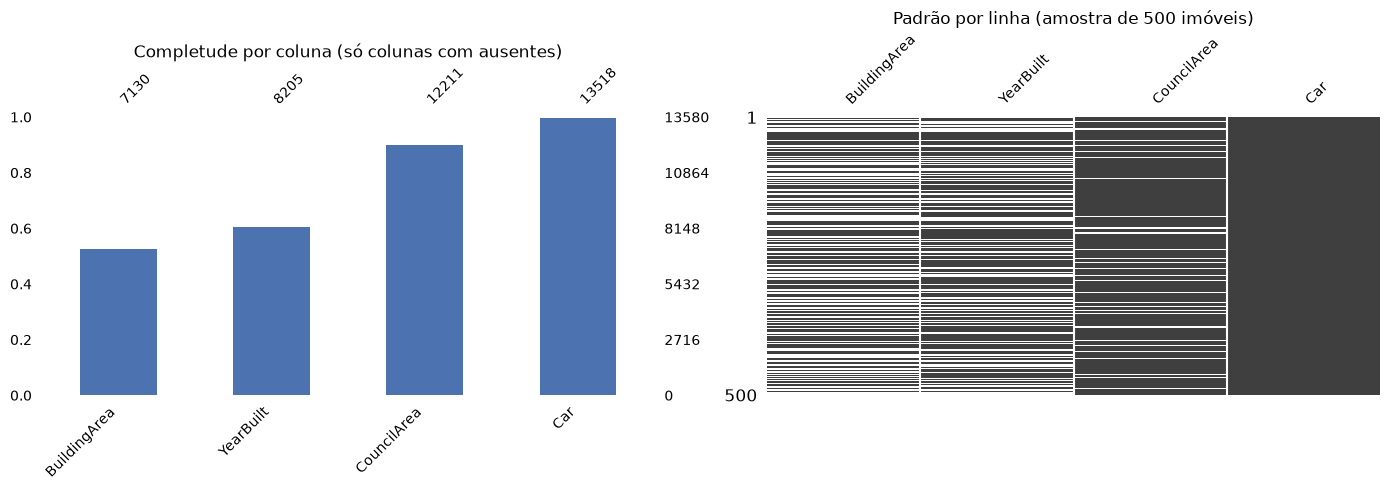

Correlação entre os indicadores de ausência (1 = sempre faltam juntas):


,BuildingArea,YearBuilt,CouncilArea,Car
BuildingArea,1.00,0.77,0.02,0.01
YearBuilt,0.77,1.00,0.04,0.01
CouncilArea,0.02,0.04,1.00,0.20
Car,0.01,0.01,0.20,1.00


In [5]:
# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
cols_aus = resumo.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
msno.bar(df[cols_aus], ax=axes[0], fontsize=10, color='#4C72B0')
axes[0].set_title('Completude por coluna (só colunas com ausentes)')
msno.matrix(df[cols_aus].sample(500, random_state=42), ax=axes[1], fontsize=10, sparkline=False)
axes[1].set_title('Padrão por linha (amostra de 500 imóveis)')
plt.tight_layout()
plt.show()

# Correlação de nulidade: as ausências aparecem juntas nas mesmas linhas?
print('Correlação entre os indicadores de ausência (1 = sempre faltam juntas):')
df[cols_aus].isna().astype(int).corr().round(2)

In [6]:
# Quantas linhas têm 0, 1, 2... colunas ausentes ao mesmo tempo?
n_aus_linha = df[cols_aus].isna().sum(axis=1)
print(n_aus_linha.value_counts().sort_index().rename('linhas').to_frame())

   linhas
0    6196
1    2136
2    4654
3     564
4      30


**O que o padrão mostra:**
- As ausências se **concentram em poucas colunas**: `BuildingArea` e `YearBuilt` respondem pela maior parte; `CouncilArea` e `Car` têm pouco.
- Elas **não são totalmente independentes**: a matriz mostra que `BuildingArea` e `YearBuilt` costumam faltar nos mesmos imóveis (correlação de nulidade de 0,77). Isso sugere um mesmo motivo de origem, como um corretor ou uma imobiliária que não preencheu esses campos. Os dados não estão faltando de forma puramente aleatória.

## Estratégia 1 — Remoção
**Decisão e justificativa**
- `BuildingArea` (≈47% ausente) e `YearBuilt` (≈40% ausente): **removo as colunas**. Imputar quase metade da coluna significaria que boa parte do valor "observado" seria inventada pelo método, e a coluna passaria a refletir mais a imputação do que o mercado.
- `Car` (0,5%) e `CouncilArea` (10%): **removo as linhas** com ausência. Depois de descartar as colunas pesadas, sobra pouca perda de linhas, e as ausências restantes são pontuais.

Também guardo uma variante (`df_remocao_linhas`) que só apaga linhas (`dropna()` em tudo), para mostrar quanto custa essa abordagem.

In [7]:
# ESTRATÉGIA 1 — REMOÇÃO
LIMITE_COLUNA = 30  # % de ausentes a partir do qual a coluna é descartada

df_remocao = df.copy()
cols_descartadas = resumo.index[resumo['pct_ausentes'] > LIMITE_COLUNA].tolist()
df_remocao = df_remocao.drop(columns=cols_descartadas).dropna()

# Variante: remover apenas linhas (mantém todas as colunas)
df_remocao_linhas = df.copy().dropna()

print('Colunas descartadas:', cols_descartadas)
print(f'df_remocao        -> {df_remocao.shape[0]:>6,} linhas x {df_remocao.shape[1]} colunas')
print(f'df_remocao_linhas -> {df_remocao_linhas.shape[0]:>6,} linhas x {df_remocao_linhas.shape[1]} colunas')
print(f'Linhas perdidas na variante só-linhas: {len(df) - len(df_remocao_linhas):,} ({(1 - len(df_remocao_linhas)/len(df))*100:.1f}%)')

Colunas descartadas: ['BuildingArea', 'YearBuilt']
df_remocao        -> 12,211 linhas x 19 colunas
df_remocao_linhas ->  6,196 linhas x 21 colunas
Linhas perdidas na variante só-linhas: 7,384 (54.4%)


## Estratégia 2 — Imputação
**Decisão e justificativa**
- Colunas numéricas (`BuildingArea`, `YearBuilt`, `Car`): **mediana**. A mediana é robusta a valores extremos (veja que `BuildingArea` tem máximo de 44.515 m², claramente um erro ou caso fora da curva) e, para `Car` e `YearBuilt`, devolve um valor que realmente existe na coluna.
- Coluna categórica (`CouncilArea`): **moda** (categoria mais frequente), a única medida estatística que faz sentido para texto.
- Para `BuildingArea` e `YearBuilt` crio também colunas indicadoras (`*_ausente`), para não perder a informação de que o dado estava faltando (ver reflexão 3).

In [8]:
# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

for col in ['BuildingArea', 'YearBuilt', 'Car']:
    if col in ('BuildingArea', 'YearBuilt'):
        df_imputacao[col + '_ausente'] = df_imputacao[col].isna().astype(int)
    df_imputacao[col] = df_imputacao[col].fillna(df[col].median())

df_imputacao['CouncilArea'] = df_imputacao['CouncilArea'].fillna(df['CouncilArea'].mode()[0])

print('Ausentes após imputação:', df_imputacao.drop(columns=['BuildingArea_ausente', 'YearBuilt_ausente']).isna().sum().sum())
print('Medianas usadas:', {c: df[c].median() for c in ['BuildingArea', 'YearBuilt', 'Car']})
print('Moda usada em CouncilArea:', df['CouncilArea'].mode()[0])

Ausentes após imputação: 0
Medianas usadas: {'BuildingArea': np.float64(126.0), 'YearBuilt': np.float64(1970.0), 'Car': np.float64(2.0)}
Moda usada em CouncilArea: Moreland


## Comparação entre as estratégias

In [9]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print('Linhas restantes por estratégia:')
print(pd.Series({
    'original': len(df),
    'remoção (colunas >30% + linhas)': len(df_remocao),
    'remoção (só linhas / dropna)': len(df_remocao_linhas),
    'imputação': len(df_imputacao),
}, name='linhas').to_frame())

cols_cmp = ['BuildingArea', 'YearBuilt', 'Car']
linhas = []
for nome, base in [('original (só valores presentes)', df), ('remoção só-linhas', df_remocao_linhas), ('imputação (mediana)', df_imputacao)]:
    for c in cols_cmp:
        s = base[c]
        linhas.append({'estratégia': nome, 'coluna': c, 'n': s.notna().sum(), 'média': s.mean(), 'mediana': s.median(), 'desvio': s.std()})
comp = pd.DataFrame(linhas).pivot(index='estratégia', columns='coluna', values=['n', 'média', 'mediana', 'desvio'])
comp

Linhas restantes por estratégia:
                                 linhas
original                          13580
remoção (colunas >30% + linhas)   12211
remoção (só linhas / dropna)       6196
imputação                         13580


n                            média                     mediana                      desvio  \
coluna                          BuildingArea       Car YearBuilt BuildingArea  Car YearBuilt BuildingArea  Car YearBuilt BuildingArea   
estratégia                                                                                                                              
imputação (mediana)                13,580.00 13,580.00 13,580.00       139.63 1.61  1,966.79       126.00 2.00  1,970.00       392.22   
original (só valores presentes)     7,130.00 13,518.00  8,205.00       151.97 1.61  1,964.68       126.00 2.00  1,970.00       541.01   
remoção só-linhas                   6,196.00  6,196.00  6,196.00       141.57 1.57  1,964.08       124.00 1.00  1,970.00        90.83   

                                                
coluna                           Car YearBuilt  
estratégia                                      
imputação (mediana)             0.96     29.09  
original (só valores presentes) 0.96     37.27  
remoção só-linhas               0.93     38.11

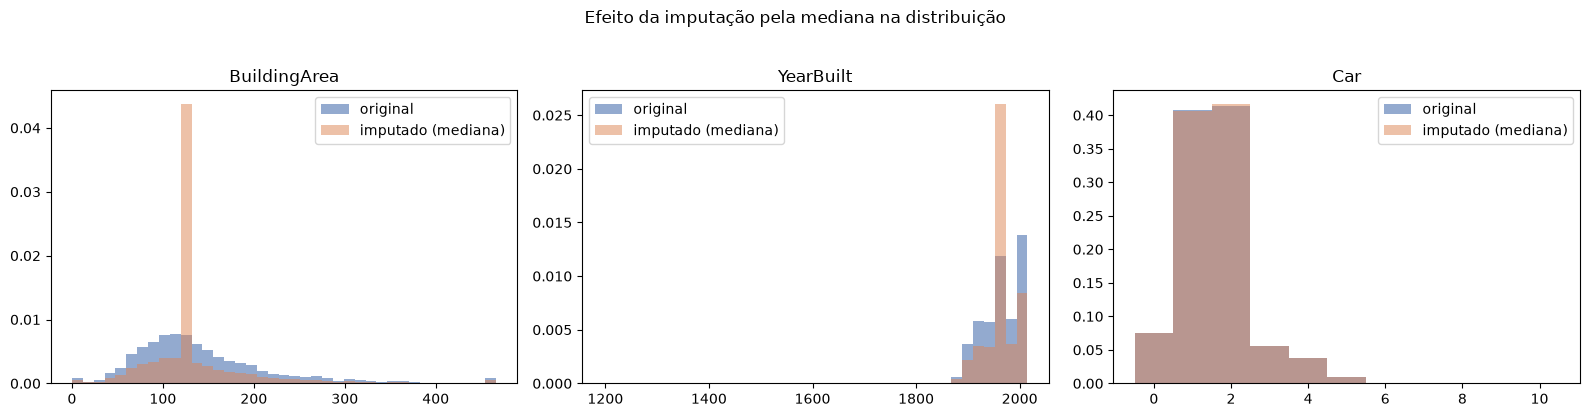

In [10]:
# Distribuições antes x depois (BuildingArea limitada ao percentil 99 só para a visualização)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cols_cmp):
    lim = df[c].quantile(0.99)
    bins = np.linspace(df[c].min(), lim, 40) if c != 'Car' else np.arange(-0.5, 11.5, 1)
    ax.hist(df[c].dropna().clip(upper=lim), bins=bins, alpha=0.6, density=True, label='original', color='#4C72B0')
    ax.hist(df_imputacao[c].clip(upper=lim), bins=bins, alpha=0.5, density=True, label='imputado (mediana)', color='#DD8452')
    ax.set_title(c)
    ax.legend()
plt.suptitle('Efeito da imputação pela mediana na distribuição', y=1.03)
plt.tight_layout()
plt.show()

**O que mudou:**
- **Remoção:** não há valor "fabricado", mas o custo é em **tamanho da base**: apagar só linhas elimina 54% dos imóveis (13.580 → 6.196), enquanto descartar as duas colunas pesadas preserva 90% das linhas (12.211) ao custo de perder duas variáveis. Além disso, apagar linhas **não é neutro**: a mediana de `Car` caiu de 2 para 1 e o desvio-padrão de `BuildingArea` caiu de 541 para 91 (o imóvel de 44.515 m² saiu junto), ou seja, os imóveis que sobraram não representam exatamente a base original.
- **Imputação:** a mediana permanece igual por construção (126 m², 1970, 2 vagas), mas o **desvio-padrão cai** (`BuildingArea` 541 → 392; `YearBuilt` 37 → 29) e o histograma ganha um **pico artificial** exatamente no valor imputado. Imputar muito em uma coluna "achata" a variabilidade real, e por isso colunas com ≈40–47% de ausência são más candidatas a essa técnica.
- **Valores suspeitos além dos ausentes:** `YearBuilt` tem mínimo de **1196** (impossível para Melbourne) e `BuildingArea` chega a **44.515 m²**. São erros de registro que a imputação não corrige. Seriam tratados na etapa de outliers (ver Exercício 4).

## Respostas às perguntas de reflexão

In [11]:
# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO — evidência numérica para a pergunta 2
evid = pd.DataFrame({
    'média': df[['Price', 'Landsize']].mean(),
    'mediana': df[['Price', 'Landsize']].median(),
    'máximo': df[['Price', 'Landsize']].max(),
})
evid['média / mediana'] = evid['média'] / evid['mediana']
evid

,média,mediana,máximo,média / mediana
Price,"1,075,684.08","903,000.00","9,000,000.00",1.19
Landsize,558.42,440.00,"433,014.00",1.27


**1. Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada? De que isso depende?**
Não há regra fixa, a decisão depende de quatro coisas:
1. **Importância da coluna para o objetivo.** Se ela é essencial (por exemplo, a variável-alvo), vale tentar recuperar os dados por outra fonte, ou aceitar a imputação com ressalvas. Se é secundária, descartar é mais honesto.
2. **Por que os dados faltam.** Se faltam ao acaso, imputar distorce menos. Se faltam por um motivo sistemático (como o que vimos entre `BuildingArea` e `YearBuilt`), a imputação pode inserir um viés.
3. **Quanta informação resta.** Com mais de 50% ausente, a maior parte da coluna viria do método, não dos dados.
4. **Existência de colunas correlacionadas** que permitam estimar o valor com qualidade (aí uma imputação por modelo, como o KNN, pode se justificar).

Neste trabalho descartei as colunas com ≈40–47% de ausência. Se o objetivo fosse prever preço e a área construída fosse decisiva, eu manteria a coluna com um indicador de ausência e testaria o impacto no modelo.

**2. Para `Price` ou `Landsize`, média e mediana dariam valores parecidos? Qual seria mais segura?**
Não. A tabela acima mostra que a média fica acima da mediana nas duas colunas (razão média/mediana de 1,19 em `Price` e 1,27 em `Landsize`), porque as distribuições são **assimétricas à direita**: poucos imóveis muito caros e terrenos enormes (`Landsize` chega a 433.014 m²) puxam a média para cima. A **mediana é mais segura**, porque um punhado de valores extremos não a desloca. A média imputada geraria um valor "típico" que na verdade não é típico de quase nenhum imóvel.

**3. Em que situação o fato de um valor estar ausente é, por si só, uma informação útil?**
Quando a ausência **carrega significado**, isto é, não é aleatória. Exemplos: em um cadastro de imóveis, `BuildingArea` ausente pode indicar terreno sem construção ou anúncio feito por um tipo específico de vendedor; em crédito, "renda não informada" pode estar associada a maior risco; em pesquisas, não responder a uma pergunta sensível já é um comportamento. Nesses casos, apagar ou imputar sem registrar a ausência joga fora um sinal. Por isso criei as colunas `BuildingArea_ausente` e `YearBuilt_ausente`: elas permitem que o modelo use a ausência como variável.

## Desafio — KNNImputer
O `KNNImputer` preenche cada valor ausente com a média dos **k vizinhos mais parecidos** (nas demais colunas numéricas), em vez de usar um valor único para todos. Aplico em `YearBuilt` com variáveis padronizadas (o KNN usa distância, então escalas diferentes distorceriam o resultado).

       original (presentes)  imputado mediana  imputado KNN (k=5)
count              8,205.00         13,580.00           13,580.00
mean               1,964.68          1,966.79            1,963.02
50%                1,970.00          1,970.00            1,967.00
std                   37.27             29.09               33.72
min                1,196.00          1,196.00            1,196.00
max                2,018.00          2,018.00            2,018.00

Valores únicos em YearBuilt -> mediana: 144 | KNN: 589 | original: 144


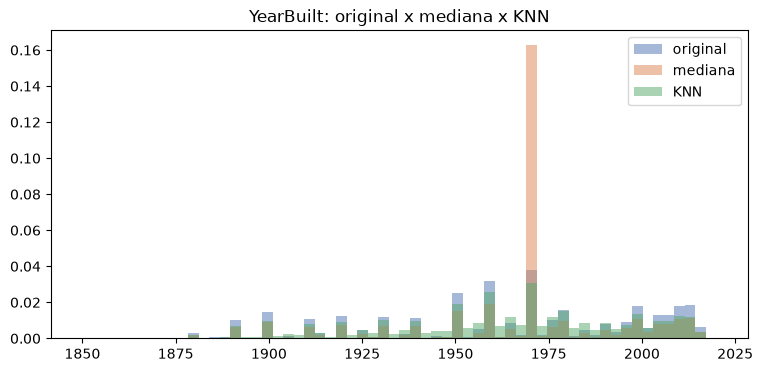

In [12]:
# DESAFIO — KNNImputer em YearBuilt
feats = ['Rooms', 'Distance', 'Bedroom2', 'Bathroom', 'Landsize', 'Lattitude', 'Longtitude', 'Price']
alvo = 'YearBuilt'

base = df[feats + [alvo]].copy()
base[feats] = base[feats].fillna(base[feats].median())   # features auxiliares com pouquíssimos ausentes
X = pd.DataFrame(StandardScaler().fit_transform(base[feats]), columns=feats, index=base.index)
X[alvo] = base[alvo]

knn = KNNImputer(n_neighbors=5)
ano_knn = pd.Series(knn.fit_transform(X)[:, -1], index=df.index, name='YearBuilt_knn')
ano_med = df_imputacao['YearBuilt']

cmp_knn = pd.DataFrame({
    'original (presentes)': df['YearBuilt'].describe(),
    'imputado mediana': ano_med.describe(),
    'imputado KNN (k=5)': ano_knn.describe(),
})
print(cmp_knn.loc[['count', 'mean', '50%', 'std', 'min', 'max']])
print('\nValores únicos em YearBuilt -> mediana:', ano_med.nunique(), '| KNN:', ano_knn.nunique(), '| original:', df['YearBuilt'].nunique())

fig, ax = plt.subplots(figsize=(9, 4))
faixa = (1850, 2020)
ax.hist(df['YearBuilt'].dropna(), bins=60, range=faixa, density=True, alpha=0.5, label='original', color='#4C72B0')
ax.hist(ano_med, bins=60, range=faixa, density=True, alpha=0.5, label='mediana', color='#DD8452')
ax.hist(ano_knn, bins=60, range=faixa, density=True, alpha=0.5, label='KNN', color='#55A868')
ax.set_title('YearBuilt: original x mediana x KNN'); ax.legend(); plt.show()

In [13]:
# Validação: escondo 10% dos anos que SÃO conhecidos e meço o erro de cada método
rng = np.random.default_rng(42)
conhecidos = df.index[df['YearBuilt'].notna()]
mask = rng.choice(conhecidos, size=int(0.1 * len(conhecidos)), replace=False)

X_val = X.copy()
verdade = X_val.loc[mask, alvo].copy()
X_val.loc[mask, alvo] = np.nan

pred_med = pd.Series(X_val[alvo].median(), index=mask)
pred_knn = pd.Series(KNNImputer(n_neighbors=5).fit_transform(X_val)[:, -1], index=X_val.index).loc[mask]

mae = pd.Series({'mediana': (pred_med - verdade).abs().mean(), 'KNN (k=5)': (pred_knn - verdade).abs().mean()}, name='erro absoluto médio (anos)')
mae.to_frame()

,erro absoluto médio (anos)
mediana,29.07
KNN (k=5),21.43


**O que muda e qual o custo do KNN:**
- **Resultado:** o KNN produz valores **diferentes para cada imóvel**, respeitando a vizinhança (casas na mesma região e com perfil parecido tendem a ter idade parecida), enquanto a mediana coloca o mesmo ano em todos. No histograma, a imputação por mediana cria um pico único; a do KNN mantém uma distribuição mais próxima da original. O desvio-padrão do KNN (33,7) fica mais perto do original (37,3) do que o da mediana (29,1). No teste de validação (esconder 10% dos anos conhecidos), o KNN erra em média **21,4 anos contra 29,1 da mediana**, o que é esperado quando existe relação entre o ano e as demais variáveis. Mesmo assim o erro é grande: o KNN melhora, mas não adivinha.
- **Custo:** (1) **computacional**: para cada valor ausente é preciso calcular distâncias contra todas as linhas, o que fica caro em bases grandes; (2) **precisa de escalonamento** e de escolher `k` e as variáveis auxiliares; (3) **complexidade e risco de vazamento**: se usado antes de separar treino e teste, a imputação "enxerga" dados do teste; (4) é **menos transparente** de explicar do que "usei a mediana"; (5) ainda gera valores **inventados** (não resolve o problema de fundo, só o disfarça melhor).

## Conclusão
| Estratégia | Linhas | Colunas | Quando usar |
|---|---|---|---|
| Remoção (colunas >30% + linhas) | 12.211 | 19 | Quando as colunas muito vazias não são essenciais e o volume de linhas importa |
| Remoção só de linhas | 6.196 | 21 | Raramente: joga fora 54% da base |
| Imputação (mediana/moda + indicador) | 13.580 | 23 | Quando todas as colunas importam e a ausência é registrada como variável |
| KNN | 13.580 | — | Quando há variáveis correlacionadas e o custo extra compensa |

Em todos os casos a base original (`df`) foi preservada e cada resultado foi guardado em um DataFrame separado.